# Representational geometry: predicted vs. learned

The project's claim: the geometry a network learns is **predictable in closed form** from the
structure of the task.

For sweeps, use the CLI instead, e.g. `python -m src.code.train -m runner=klinear setting=graph structure=ring,chain`.

In [7]:
import sys
import numpy as np
from pyprojroot import here
sys.path.append(str(here()))

from src.code.data import graph_conditional
from src.code.geometry import predicted_geometry
from src.code.eval import cka, rsa
from src.code.train import train_inline, graph_overrides
from src.code import plot_utils           # importing this applies the house plotting style

## 1. The predicted geometry (closed form)

Factor the ring's log-conditional — no training. The translation symmetry gives a degenerate
top Fourier pair, and the top-2 code lands on a circle.

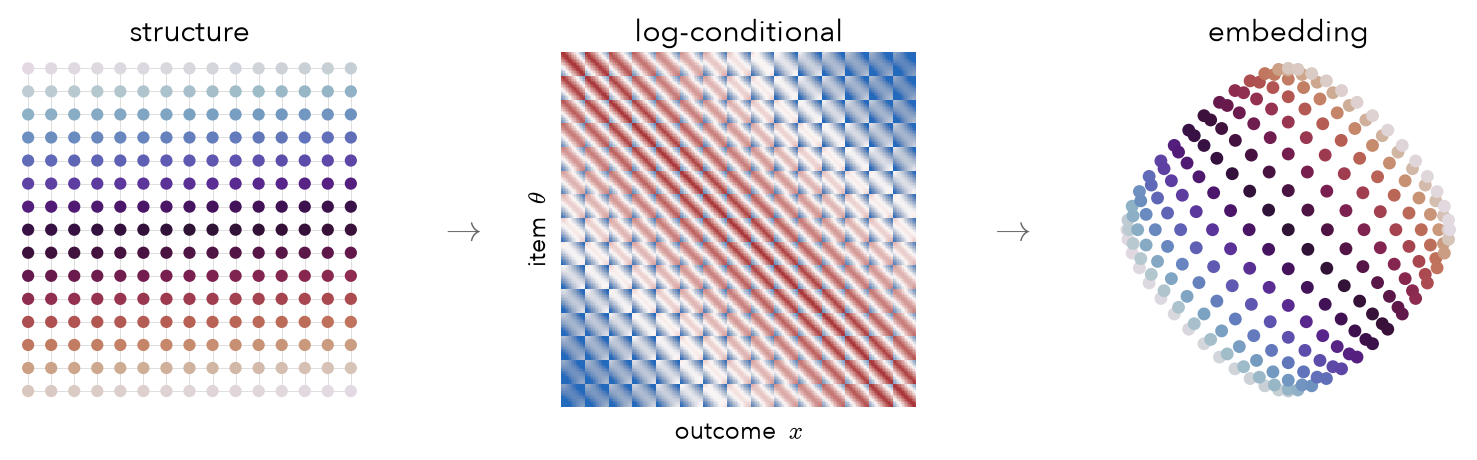

In [8]:
# pick a structure here — everything below follows from it
spec = {"structure": "grid", "n": 15}   # e.g. {"structure": "chain", "n": 24} or {"structure": "grid", "n": 6, "m": 6}
L = graph_conditional(spec)
E_pred = predicted_geometry(L)
plot_utils.plot_predicted_geometry(spec, L, E_pred);

## 2. Train the model ladder inline

Train four architectures on the *same* ring task — a transformer (on Markov walks) and k-linear /
MLP / RNN readouts (on item→neighbor pairs) — each from a prespecified runner, no terminal.
`train_inline` returns the live model + an in-memory history, so we can watch the geometry form.

Current GPUs:
    GPU 0: NVIDIA H200
wandb disabled (wandb.enabled=false); skipping wandb.init.


INFO:src.code.models:Number of parameters: 18496


Model dims from dataset: vocab_size=25, max_position_embeddings=25


Step,Training Loss
100,2.245001
200,2.081200
300,2.076006
400,2.075285
500,2.077800
600,2.075172
700,2.077335
800,2.073243


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

INFO:src.code.models:Number of parameters: 17769


mlp          CKA=0.981  RSA=0.967
Current GPUs:
    GPU 0: NVIDIA H200
wandb disabled (wandb.enabled=false); skipping wandb.init.
Model dims from dataset: vocab_size=25, num_classes=24, arity=1


Step,Training Loss
100,2.302409
200,2.079111
300,2.074616
400,2.074277
500,2.076892
600,2.074234
700,2.076996
800,2.072875
900,2.074943
1000,2.074035


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

rnn          CKA=0.991  RSA=0.982


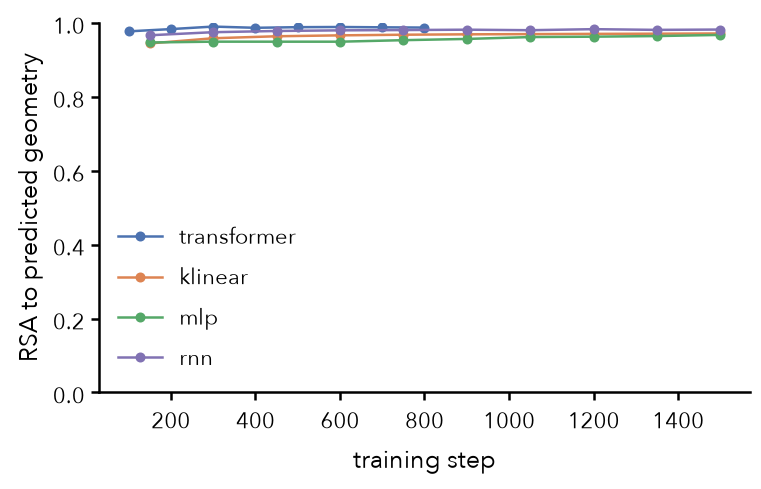

In [3]:
ARCHS = ["transformer", "klinear", "mlp", "rnn"]
results = {}
for arch in ARCHS:
    model, dataset, evaluator, history = train_inline(graph_overrides(spec) + [f"runner={arch}"])
    E_true = predicted_geometry(dataset.conditional)                       # matches the trained items
    reps = evaluator.item_representations(model)                            # pre-decode activations
    results[arch] = {"reps": reps, "history": history,
                     "cka": cka(reps, E_true), "rsa": rsa(reps, E_true)}
    print(f"{arch:12s} CKA={results[arch]['cka']:.3f}  RSA={results[arch]['rsa']:.3f}")

plot_utils.plot_rsa_curves({a: results[a]["history"] for a in ARCHS});

## 3. Learned embeddings & representational convergence

Every architecture's token embedding (PCA to 2-D) beside the closed-form prediction — they land on
the same circle, up to a rotation/reflection CKA/RSA are invariant to. The bars quantify the match;
linear-readout heads (k-linear) print the geometry most sharply, since a nonlinear head can offload
structure into its weights instead of the embedding.

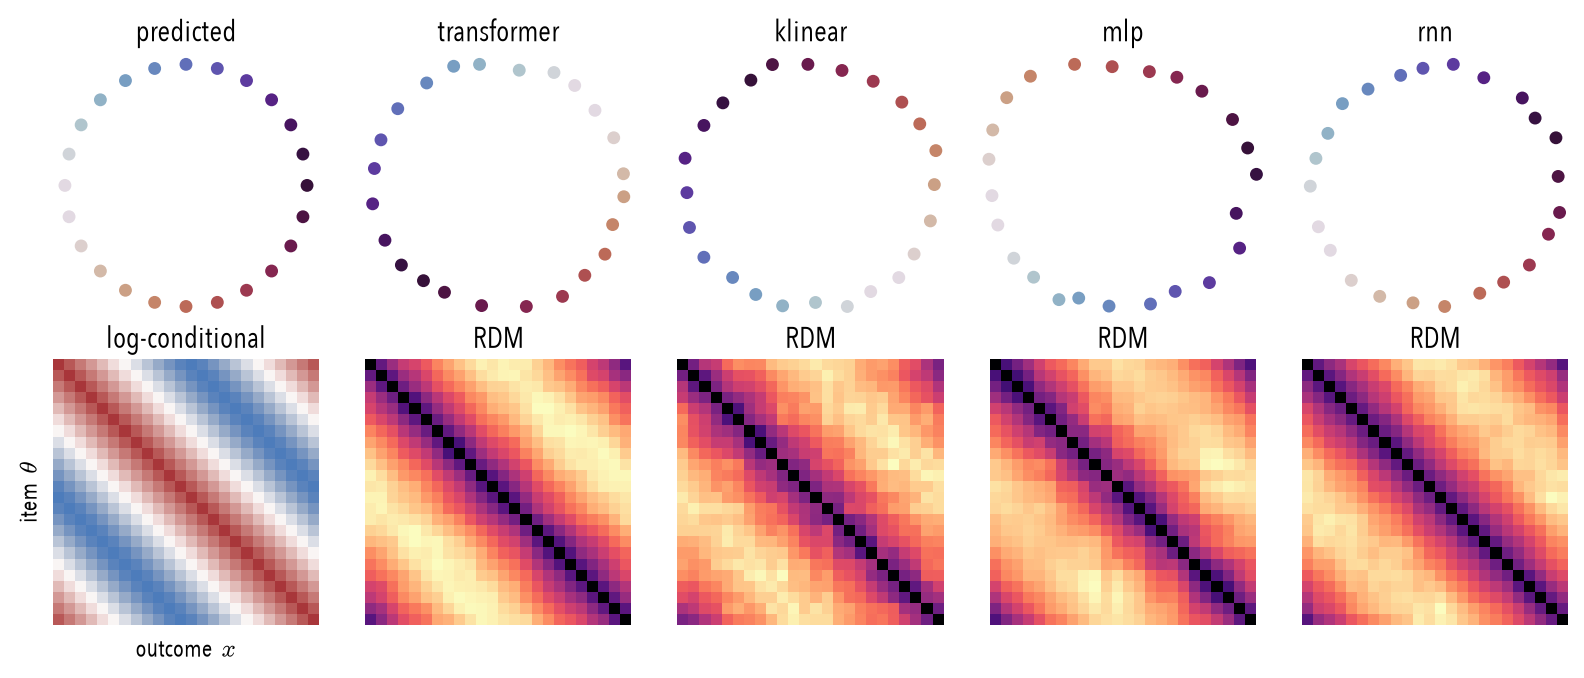

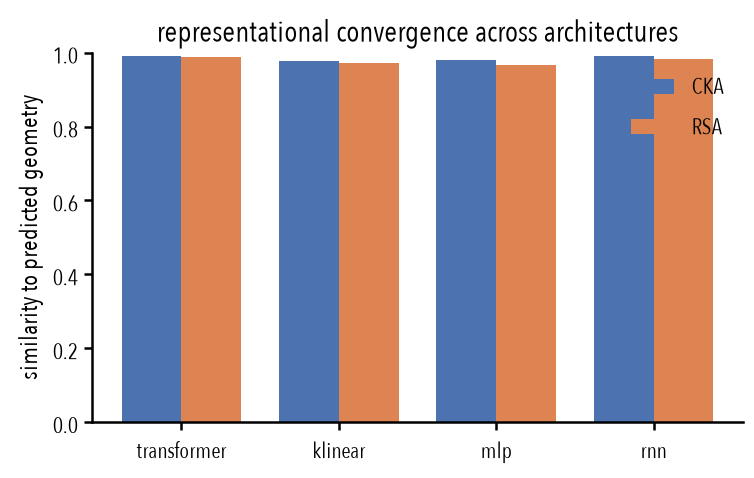

In [4]:
plot_utils.plot_embedding_panels(E_pred, {a: results[a]["reps"] for a in ARCHS}, L)
plot_utils.plot_convergence_bars({a: {"cka": results[a]["cka"], "rsa": results[a]["rsa"]} for a in ARCHS});